In [1]:
import torch
from torch.distributions import MultivariateNormal
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
import torch.nn as nn
from torch.distributions import Uniform
import gc
import math
import time


plt.style.use(['science', 'notebook', 'grid'])
torch.set_default_device("cuda")
torch.manual_seed(0)

covariance computation time: 35.08415750000859


c:\Users\erics\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\autograd\graph.py:882: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:370.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


loop time: 49.75520999869332
Step: 0, Loss: 754.0411376953125
Validation error (rel-rmse): 127.43155670166016
Training set error (rel-rmse): 127.4715576171875

loop time: 27.22860999929253
Step: 100, Loss: -159.02947998046875
Validation error (rel-rmse): 97.46617889404297
Training set error (rel-rmse): 97.49369812011719

loop time: 24.982729999464937
Step: 200, Loss: -343.987548828125
Validation error (rel-rmse): 94.44960021972656
Training set error (rel-rmse): 94.59381866455078

loop time: 29.218459999538027
Step: 300, Loss: -508.53387451171875
Validation error (rel-rmse): 91.79403686523438
Training set error (rel-rmse): 92.0550308227539

loop time: 23.904689998016693
Step: 400, Loss: -651.1279907226562
Validation error (rel-rmse): 89.40099334716797
Training set error (rel-rmse): 89.75564575195312

loop time: 24.522219999926165
Step: 500, Loss: -768.5457763671875
Validation error (rel-rmse): 87.19940185546875
Training set error (rel-rmse): 87.64508056640625

loop time: 26.376800000434

C:\Users\erics\AppData\Local\Temp\ipykernel_15060\824820006.py:205: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right', fontsize=10)


Text(0, 0.5, 'error')

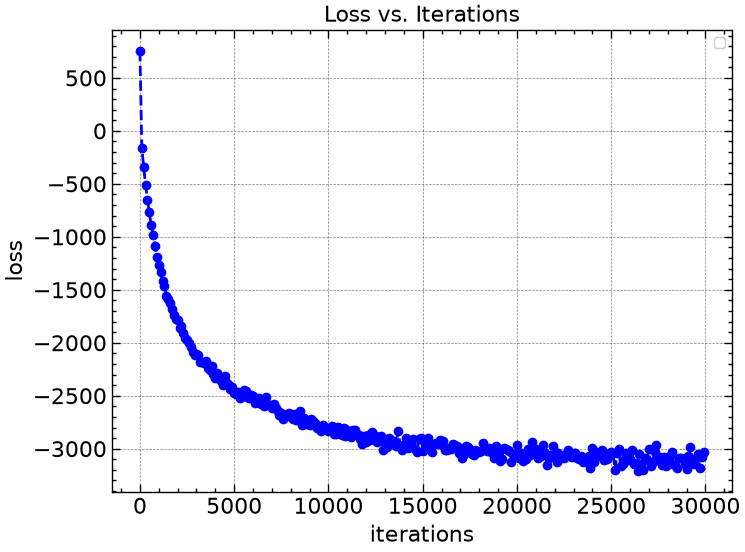

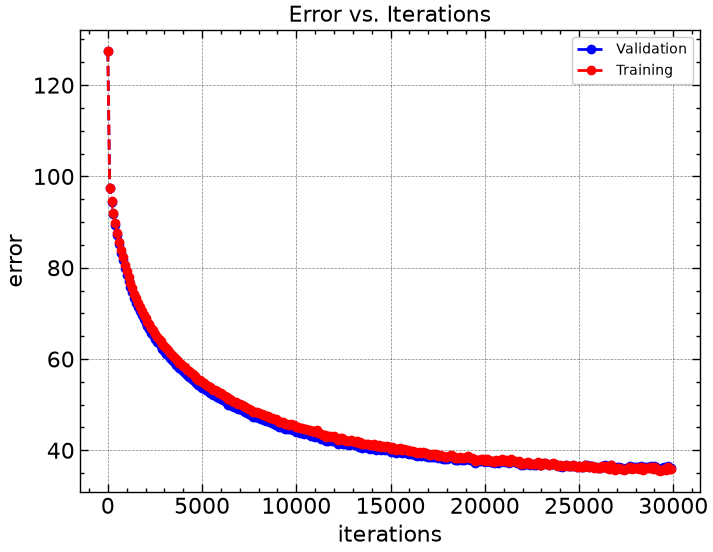

In [2]:
d = 30
    # Image height and width
N = 15000
    # Number of samples
lr = .003
    # Learning rate
steps = 30000
    # Number optimization iterations
M = 1
    # How many random vectors to estimate Hessian trace
B = 256
    # Mini batch size


mu = torch.ones(d ** 2,)

var = 2
L = 1
eps = .000

st1 = time.perf_counter()
def cov_comp(var, L):
    temp = torch.zeros(d ** 2, d ** 2)
    for n in range(temp.shape[0]):
            i_1 = n // d
            j_1 = n % d
            for m in range(temp.shape[1]):
                i_2 = m // d
                j_2 = m % d

                di = abs(i_1 - i_2)
                dj = abs(j_1 - j_2)

                di = min(di, d - di)
                dj = min(dj, d - dj)

                dist_squared = (di) ** 2 + (dj) ** 2
                temp[m][n] = (var ** 2) * math.exp(- dist_squared / (2 * (L ** 2)))
    return temp

cov = cov_comp(var, L) + torch.eye(d ** 2,) * eps

et1 = time.perf_counter()

print(f"covariance computation time: {et1 - st1}")


dist = MultivariateNormal(mu, cov)
samples = dist.sample((N,)).detach().requires_grad_(True)

score_nn = nn.Linear(d ** 2, d ** 2, bias=True)
optimizer = torch.optim.Adam(score_nn.parameters(), lr=lr)


tr_dist = MultivariateNormal(torch.zeros(d **2, ), torch.eye(d ** 2, ))
def trace(score, data, i):
    tr_sample = tr_dist.sample((i,))
    vec_hess = torch.autograd.grad(outputs = score(data), inputs = data, grad_outputs=tr_sample, create_graph=True, retain_graph=True, is_grads_batched=True,)[0]
    return (tr_sample * vec_hess).sum(dim=1).mean()

    


     
def loss(score, data):
    vals = score(data)
    norm = 0.5 * vals.square().sum(dim=1)
    ttrace = torch.stack([trace(score, x,M) for x in data])
    return (ttrace + norm).mean()







storex = torch.zeros(steps // 100, )
storey = torch.zeros(steps // 100, )


train_estorex = torch.zeros(steps // 100, )
train_estorey = torch.zeros(steps // 100, )

val_estorex = torch.zeros(steps // 100, )
val_estorey = torch.zeros(steps // 100, )

test_set = dist.sample((N,)).requires_grad_()

def rmse(act,learned,x):
    return (((learned(x) - act(x)) ** 2).mean()) ** 0.5
    # Sqrt of mean squared error
        # .mean(): mean along all entries in tensor


def rel_rmse(act,learned,x):
    denom = ((act(x) ** 2).mean()) ** 0.5
        # Mean of actual squared
    return (rmse(act,learned,x) / denom) * 100
        # Used to make sqrt of MSE a unitless percen    tage for easy interpretability

def actual(x):
    return (torch.linalg.inv(cov) @ (mu - x).T).T

def EVS(x):
    return (x.abs() ** 2).mean(dim=0)

for step in range(steps):
    stl = time.perf_counter()
        # Main training loop
    
    # st2 = time.perf_counter()
    with torch.no_grad():
        indices = torch.randperm(N, device=samples.device)[:B]
    batch = samples[indices].detach().requires_grad_(True)
    loss_store = loss(score_nn, batch)
    # et2 = time.perf_counter()
    # print(f"Loss calc + trace: {et2-st2}")

    # st3 = time.perf_counter()
    optimizer.zero_grad()
    # et3 = time.perf_counter()
    # print(f"zero out grads calc: {et3-st3}")

            # Clear out gradients to not add from last loop
    # st3 = time.perf_counter()
    loss_store.backward()
    # et3 = time.perf_counter()
    # print(f"backprop calc: {et3-st3}")

        # Calculates gradients with respect to parameters in Adam
    # st4 = time.perf_counter()
    optimizer.step()
    # et4 = time.perf_counter()
    # print(f"grad decent calc: {et4-st4}")
    etl = time.perf_counter()
    if step % 100 == 0:
        print(f"loop time: {100 * (etl - stl)}")



        # Calculated the Adam gradient descent
    if step % 100 == 0:
        print(f"Step: {step}, Loss: {loss_store}")
        with torch.no_grad():
            storex[step // 100] = step
            storey[step // 100] = loss_store
            
            val_estorex[step // 100] = step
            val_estorey[step // 100] = rel_rmse(actual,score_nn,test_set)
            val_error_eval = rel_rmse(actual,score_nn,test_set)

            train_estorex[step // 100] = step
            train_estorey[step // 100] = rel_rmse(actual,score_nn,samples)
            train_error_eval = rel_rmse(actual,score_nn,samples)
    

        print(f"Validation error (rel-rmse): {val_error_eval}")
        print(f"Training set error (rel-rmse): {train_error_eval}")
        print("")


    # if step == 1800:
    #     for param_group in optimizer.param_groups:
    #        param_group["lr"] = 0.00003
    # if step == 5000:
    #     for param_group in optimizer.param_groups:
    #         param_group["lr"] = 0.00008





print(f"Error evaluated on training set (rel-rmse): {rel_rmse(actual,score_nn,samples)}")



storex = storex.detach().cpu().numpy()
storey = storey.detach().cpu().numpy()



train_estorex = train_estorex.detach().cpu().numpy()
train_estorey = train_estorey.detach().cpu().numpy()

val_estorex = val_estorex.detach().cpu().numpy()
val_estorey = val_estorey.detach().cpu().numpy()


# plt.figure()
# plt.imshow(EVS(actual(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=EVS(score_nn(test_set)).min().item(), vmax=EVS(score_nn(test_set)).max().item())
# plt.colorbar(label="Real EVS Score")
# plt.axis("off")


# plt.figure()
# plt.imshow(EVS(score_nn(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=EVS(score_nn(test_set)).min().item(), vmax=EVS(score_nn(test_set)).max().item())
# plt.colorbar(label="Learned EVS Score")
# plt.axis("off")

# lr tone down

plt.figure()
plt.title("Loss vs. Iterations")
plt.plot(storex, storey, 'o--', color='blue')
plt.legend(loc='upper right', fontsize=10)
plt.xlabel('iterations')
plt.ylabel('loss')

plt.figure()
plt.title("Error vs. Iterations")
plt.plot(val_estorex, val_estorey, 'o--', color='blue', label='Validation')
plt.plot(train_estorex, train_estorey, 'o--', color='red', label='Training')
plt.legend(loc='upper right', fontsize=10)
plt.xlabel('iterations')
plt.ylabel('error')


(np.float64(-0.5), np.float64(29.5), np.float64(29.5), np.float64(-0.5))

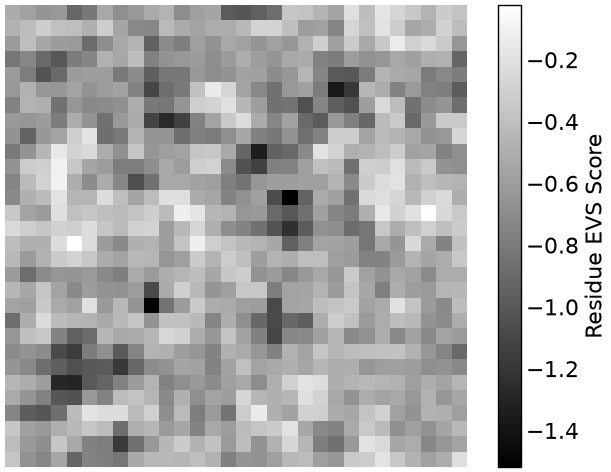

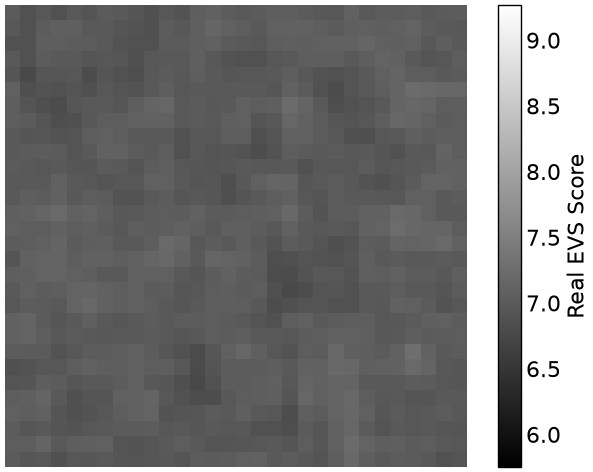

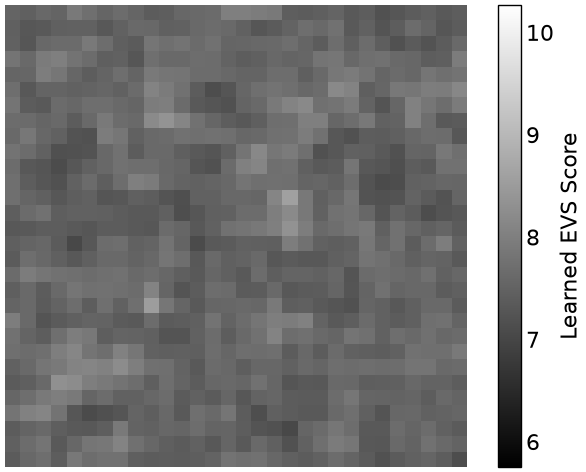

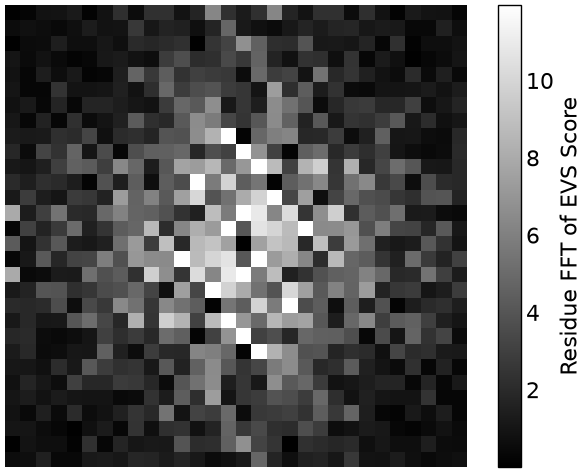

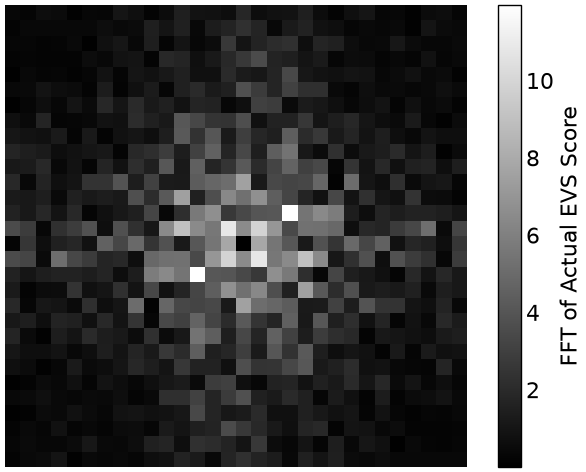

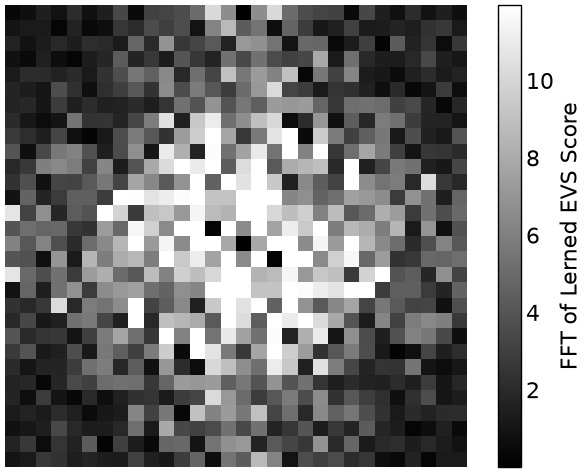

In [3]:




plt.figure()
plt.imshow(EVS(actual(test_set)).reshape(d, d).detach().cpu().numpy() - EVS(score_nn(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", )
plt.colorbar(label="Residue EVS Score")
plt.axis("off")

plt.figure()
plt.imshow(EVS(actual(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=EVS(actual(test_set)).min().item() - 1, vmax=EVS(actual(test_set)).max().item() + 2)
plt.colorbar(label="Real EVS Score")
plt.axis("off")


plt.figure()
plt.imshow(EVS(score_nn(test_set)).reshape(d, d).detach().cpu().numpy(), cmap="gray", vmin=EVS(actual(test_set)).min().item() - 1, vmax=EVS(actual(test_set)).max().item() + 3)
plt.colorbar(label="Learned EVS Score")
plt.axis("off")




# fim_raw_res = EVS((actual(test_set) - score_nn(test_set)))
# fim_res = torch.fft.fft2(fim_raw_res.reshape(d, d))

# fim_raw_act = EVS(actual(test_set))
# fim_act = torch.fft.fft2(fim_raw_act.reshape(d, d))

# fim_raw_score = EVS(score_nn(test_set))
# fim_score = torch.fft.fft2(fim_raw_score.reshape(d, d))



fim_raw_res = EVS((actual(test_set) - score_nn(test_set)))
fim_res = torch.fft.fft2((fim_raw_res.reshape(d, d) - fim_raw_res.reshape(d, d).mean()))

fim_raw_act = EVS(actual(test_set))
fim_act = torch.fft.fft2((fim_raw_act.reshape(d, d) - fim_raw_act.reshape(d, d).mean()))

fim_raw_score = EVS(score_nn(test_set))
fim_score = torch.fft.fft2((fim_raw_score.reshape(d, d) - fim_raw_score.reshape(d, d).mean()))



plt.figure()
plt.imshow(torch.fft.fftshift(fim_res, dim=(0, 1)).abs().detach().cpu().numpy(), cmap="gray", vmin=fim_act.abs().min().item() , vmax=fim_act.abs().max().item() + 0)
plt.colorbar(label="Residue FFT of EVS Score")
plt.axis("off")


plt.figure()
plt.imshow(torch.fft.fftshift(fim_act, dim=(0, 1)).abs().detach().cpu().numpy(), cmap="gray", vmin=fim_act.abs().min().item() , vmax=fim_act.abs().max().item() + 0)
plt.colorbar(label="FFT of Actual EVS Score")
plt.axis("off")


plt.figure()
plt.imshow(torch.fft.fftshift(fim_score, dim=(0, 1)).abs().detach().cpu().numpy(), cmap="gray", vmin=fim_act.abs().min().item() , vmax=fim_act.abs().max().item() + 0)
plt.colorbar(label="FFT of Lerned EVS Score")
plt.axis("off")
